In [1]:
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import sys

sys.path.append('..')

from models.PRUSR.model import PRUSR
from models.PRUSR import config
from datasets.super_res_dataset_fourier import SuperResDataset
from datasets.sr_tiny_dataset import SRTinyDataset
from metrics.image_metrics import mseLoss, ssimLoss, psnrLoss, lpipsLoss, fsimLoss, epiLoss
from metrics.physical_metrics import LossTKE
from metrics.kinetic_energy_spectrum import KineticEnergySpectrumLoss, WeightedKineticEnergySpectrumLoss
from typing import Tuple
from tqdm import tqdm
from scipy.fft import fft2

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


c:\Users\vinic\OneDrive\Área de Trabalho\Mestrado\tese-vinicius\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\vinic\OneDrive\Área de Trabalho\Mestrado\tese-vinicius\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\vinic\OneDrive\Área de Trabalho\Mestrado\tese-vinicius\.venv\Lib\site-packages\lpips\weights\v0.1\vgg.pth


In [2]:
# # In your evaluation script
# from models import DSCMS


test_dataset = SuperResDataset(
    hr_files=['../data/100/window_2023.npy'],
    downsample_factor=1,
    freq_threshold=5
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,  # or smaller if memory is tight
    shuffle=False  # Don't shuffle test data
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load checkpoint
checkpoint = torch.load('../weights/PRUSR_best_freq.pth',
                       map_location=torch.device(device))

# Extract just the model state dict
model = PRUSR(2, 2)
model = torch.nn.DataParallel(model)
model = model.to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

(1000, 128, 128, 6)


DataParallel(
  (module): PRUSR(
    (activation): LeakyReLU(negative_slope=0.2)
    (ps1_layers): Sequential(
      (0): LeakyReLU(negative_slope=0.2)
      (1): Conv2d(2, 16, kernel_size=(5, 5), stride=(1, 1), padding=same)
      (2): PRB(
        (conv_layers): Sequential(
          (0): LeakyReLU(negative_slope=0.2, inplace=True)
          (1): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
          (2): LeakyReLU(negative_slope=0.2, inplace=True)
          (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
          (4): LeakyReLU(negative_slope=0.2, inplace=True)
          (5): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
        )
      )
      (3): PRB(
        (conv_layers): Sequential(
          (0): LeakyReLU(negative_slope=0.2, inplace=True)
          (1): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
          (2): LeakyReLU(negative_slope=0.2, inplace=T

In [3]:
def evaluate_model(model, test_loader, device):
    model.eval()
    
    metrics = {
        'mse': {'u': [], 'v': []},
        'ssim': {'u': [], 'v': []},
        'psnr': {'u': [], 'v': []},
        'lpips': {'u': [], 'v': []},
        'fsim': {'u': [], 'v': []},
        'epi':{'u': [], 'v': []},
        'tke': {'u': [], 'v': []}
    }
    
    with torch.no_grad():
        for idx, (lr, hr) in tqdm(enumerate(test_loader)):
            lr, hr = lr.to(device), hr.to(device)
            output = model(lr)
            # Compute metrics for each channel
            for channel in range(2):  # u and v components
                channel_label = 'u' if channel == 0 else 'v'
                metrics['mse'][f'{channel_label}'].append(mseLoss(output, hr, channel, idx))
                metrics['ssim'][f'{channel_label}'].append(ssimLoss(output, hr, channel, idx))
                metrics['psnr'][f'{channel_label}'].append(psnrLoss(output, hr, channel, idx))
                metrics['lpips'][f'{channel_label}'].append(lpipsLoss(output, hr, channel, idx))
                metrics['fsim'][f'{channel_label}'].append(fsimLoss(output, hr, channel, idx))
                metrics['epi'][f'{channel_label}'].append(epiLoss(output, hr, channel, idx))
                metrics['tke'][f'{channel_label}'].append(LossTKE(output, hr, channel, idx))

    # Aggregate results
    results = {k: {'u': {'mean': np.mean(v['u']), 'std': np.std(v['u'])},
                    'v': {'mean': np.mean(v['v']), 'std': np.std(v['v'])}}
               for k, v in metrics.items()}
    return results

In [4]:
def interpolate_baseline(lr, mode, downsample_factor=4):
    """Generate baseline output by interpolating the coarse field back to HR size.
    lr has shape [B, C, H, W] where H, W are already the upsampled (nearest) dimensions.
    We first downsample back to the coarse grid, then interpolate with the chosen mode.
    """
    coarse_h = lr.shape[2] // downsample_factor
    coarse_w = lr.shape[3] // downsample_factor
    # Recover the coarse field via adaptive avg pool (reverses nearest-neighbor replication)
    coarse = F.adaptive_avg_pool2d(lr, (coarse_h, coarse_w))
    # Upsample with the desired interpolation mode
    output = F.interpolate(coarse, size=(lr.shape[2], lr.shape[3]), mode=mode,
                           align_corners=False if mode != 'nearest' else None)
    return output

642


C:\Users\vinic\AppData\Local\Temp\ipykernel_30240\483632122.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


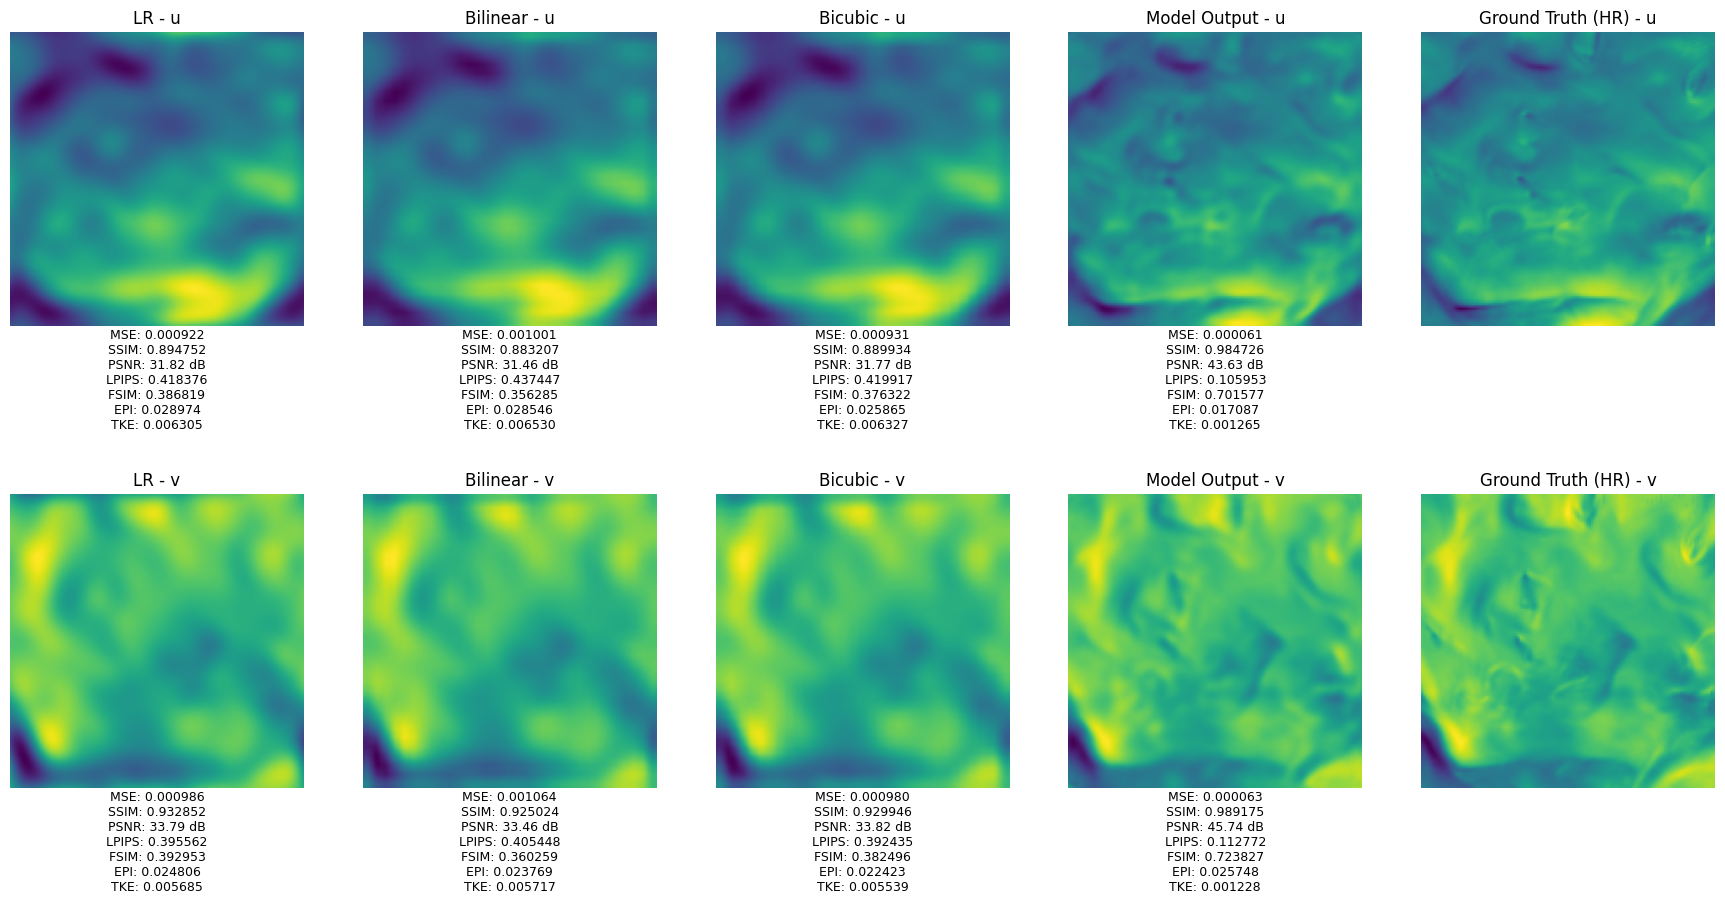

In [5]:
import matplotlib.pyplot as plt
import random

# Selection and Inference
# random_idx = 218 # Fixed as per your snippet
random_idx = random.randint(0, len(test_dataset) - 1)
random_idx=642
print(random_idx)
lr, hr = test_dataset[random_idx]
lr, hr = lr.unsqueeze(0).to(device), hr.unsqueeze(0).to(device)

output = model(lr)
bil = interpolate_baseline(lr, mode='bilinear', downsample_factor=4)
bic = interpolate_baseline(lr, mode='bicubic', downsample_factor=4)

# Increase columns to 5 and adjust figsize for the width
fig, axes = plt.subplots(2, 5, figsize=(22, 10), gridspec_kw={'hspace': 0.5}) 

for channel in range(2):
    channel_label = 'u' if channel == 0 else 'v'
    
    # --- 1. Low-resolution (LR) ---
    axes[channel, 0].imshow(lr[0][channel].cpu().numpy())
    axes[channel, 0].set_title(f'LR - {channel_label}')
    axes[channel, 0].axis('off')
    
    # Metric helper function to avoid repetition
    def add_metrics(ax, pred, target, ch):
        mse_v = mseLoss(pred.detach(), target.detach(), ch, 0)
        ssim_v = ssimLoss(pred.detach(), target.detach(), ch, 0)
        psnr_v = psnrLoss(pred.detach(), target.detach(), ch, 0)
        lpips_v = lpipsLoss(pred.detach(), target.detach(), ch, 0)
        fsim_v = fsimLoss(pred.detach(), target.detach(), ch, 0)
        epi_v = epiLoss(pred.detach(), target.detach(), ch, 0)
        tke_v = LossTKE(pred.detach(), target.detach(), ch, 0)
        
        ax.text(0.5, -0.35, 
                f'MSE: {mse_v:.6f}\nSSIM: {ssim_v:.6f}\nPSNR: {psnr_v:.2f} dB\n'
                f'LPIPS: {lpips_v:.6f}\nFSIM: {fsim_v:.6f}\nEPI: {epi_v:.6f}\nTKE: {tke_v:.6f}',
                transform=ax.transAxes, ha='center', fontsize=9)

    # Metrics for LR (as in your original code)
    add_metrics(axes[channel, 0], lr, hr, channel)

    # --- 2. Bilinear ---
    axes[channel, 1].imshow(bil[0][channel].detach().cpu().numpy())
    axes[channel, 1].set_title(f'Bilinear - {channel_label}')
    axes[channel, 1].axis('off')
    add_metrics(axes[channel, 1], bil, hr, channel)

    # --- 3. Bicubic ---
    axes[channel, 2].imshow(bic[0][channel].detach().cpu().numpy())
    axes[channel, 2].set_title(f'Bicubic - {channel_label}')
    axes[channel, 2].axis('off')
    add_metrics(axes[channel, 2], bic, hr, channel)

    # --- 4. Model Output ---
    axes[channel, 3].imshow(output[0][channel].detach().cpu().numpy())
    axes[channel, 3].set_title(f'Model Output - {channel_label}')
    axes[channel, 3].axis('off')
    add_metrics(axes[channel, 3], output, hr, channel)

    # --- 5. High-resolution (HR) ---
    axes[channel, 4].imshow(hr[0][channel].cpu().numpy())
    axes[channel, 4].set_title(f'Ground Truth (HR) - {channel_label}')
    axes[channel, 4].axis('off')

plt.tight_layout()
plt.show()

In [6]:
def compute_ek(u, v):
    u_prime = u - np.mean(u)
    v_prime = v - np.mean(v)
    nx, ny = u.shape

    # Generate wavenumbers
    kx = np.fft.fftfreq(nx) * nx
    ky = np.fft.fftfreq(ny) * ny
    kx_grid, ky_grid = np.meshgrid(kx, ky, indexing="ij")

    # Calculate radial distance from center
    k = np.sqrt(kx_grid**2 + ky_grid**2)

    # Convert fluctuations to frequency space AND Normalize
    # The (nx * ny) factor normalizes the FFT, and squaring it scales the energy correctly
    e_u = (np.abs(fft2(u_prime)) / (nx * ny)) ** 2
    e_v = (np.abs(fft2(v_prime)) / (nx * ny)) ** 2

    # Compute discrete kinetic energy
    e_k = 0.5 * (e_u + e_v)

    # Set bins from 1 up to the Nyquist frequency (nx // 2)
    # Using integer bins 1, 2, 3... up to 64
    k_bins = np.arange(1, (nx // 2) + 1, 1)

    valid_bins = []
    valid_energy = []

    # Integrate over concentric rings
    for i in range(len(k_bins) - 1):
        k_min = k_bins[i]
        k_max = k_bins[i + 1]
        mask = (k >= k_min) & (k < k_max) # The "shell"

        # Include any shell that has valid points (avoids dropping k=1)
        if np.count_nonzero(mask) > 0:
            valid_bins.append(k_min) # Or use the midpoint: 0.5 * (k_min + k_max)
            valid_energy.append(np.sum(e_k[mask]))

    return np.array(valid_bins), np.array(valid_energy)

In [7]:
def save_arrays(arr, path):
    """Save a numpy array to a .npy file."""
    np.save(path, arr)
    return path

C:\Users\vinic\AppData\Local\Temp\ipykernel_30240\1159369533.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(h_pad=2.0)


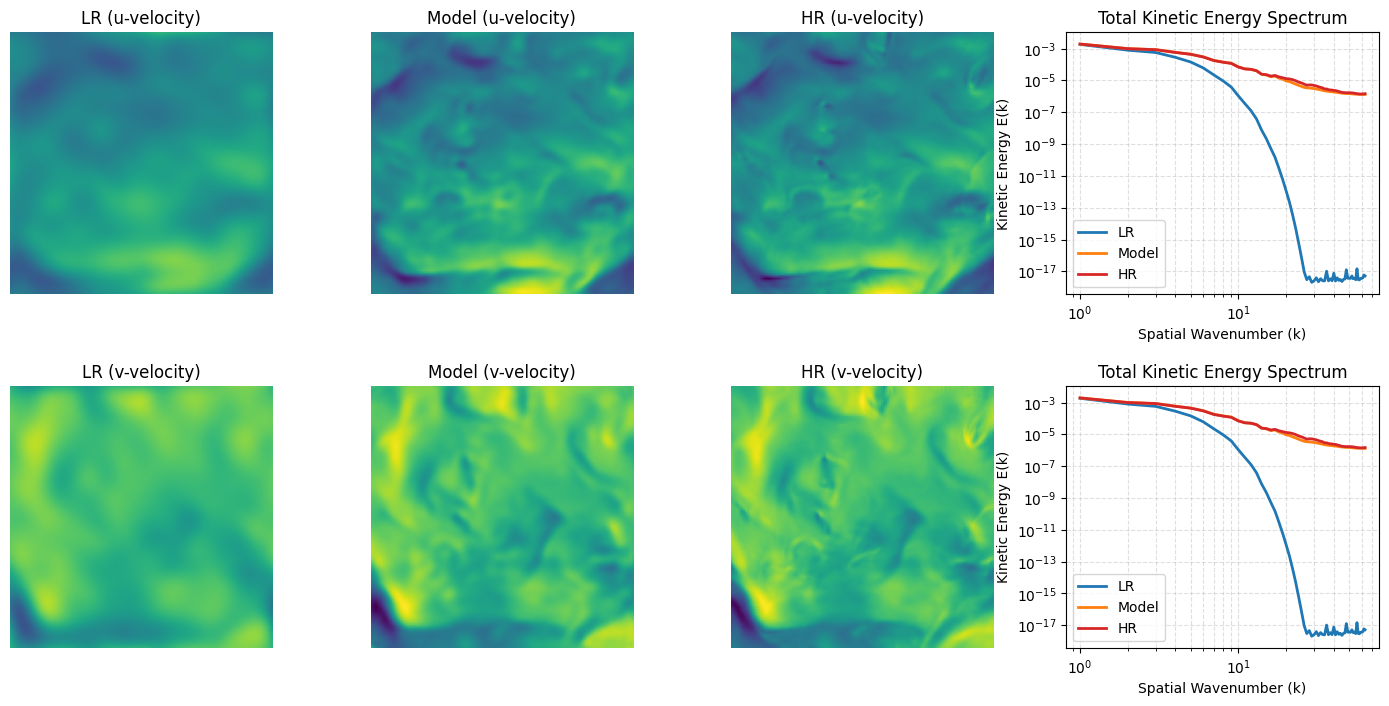

In [8]:
# 1. Compute the total kinetic energy spectrum ONCE using the full (2, H, W) arrays
lr_np = lr.squeeze(0).cpu().numpy()
pred_np = output.squeeze(0).detach().cpu().numpy()
hr_np = hr.squeeze(0).cpu().numpy()

k_lr, E_lr = compute_ek(*lr_np)
k_pred, E_pred = compute_ek(*pred_np)
k_hr, E_hr = compute_ek(*hr_np)

# 2. Set up the 2x4 grid
fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 8),
    gridspec_kw={"width_ratios": [1, 1, 1, 1], "wspace": 0.15, "hspace": 0.35}
)

variables = ["u-velocity", "v-velocity"]

for row, comp_name in enumerate(variables):
    # Determine color limits based on all fields so they share the exact same scale
    vmin = min(lr_np[row].min(), pred_np[row].min(), hr_np[row].min())
    vmax = max(lr_np[row].max(), pred_np[row].max(), hr_np[row].max())
    
    # Column 1: Low Resolution Input
    axes[row, 0].imshow(lr_np[row], vmin=vmin, vmax=vmax, cmap="viridis")
    axes[row, 0].set_title(f"LR ({comp_name})")
    axes[row, 0].axis("off")
    
    # Column 2: Model Prediction
    axes[row, 1].imshow(pred_np[row], vmin=vmin, vmax=vmax, cmap="viridis")
    axes[row, 1].set_title(f"Model ({comp_name})")
    axes[row, 1].axis("off")
    
    # Column 3: High Resolution Ground Truth
    axes[row, 2].imshow(hr_np[row], vmin=vmin, vmax=vmax, cmap="viridis")
    axes[row, 2].set_title(f"HR ({comp_name})")
    axes[row, 2].axis("off")
    
    # Column 4: Kinetic Energy Spectrum (Log-Log)
    # This plots the same overall Total Kinetic Energy spectrum on both rows
    axes[row, 3].loglog(k_lr, E_lr, label="LR", linewidth=2, color="tab:blue")
    axes[row, 3].loglog(k_pred, E_pred, label="Model", linewidth=2, color="tab:orange")
    axes[row, 3].loglog(k_hr, E_hr, label="HR", linewidth=2, color="tab:red")
    
    axes[row, 3].set_xlabel("Spatial Wavenumber (k)")
    axes[row, 3].set_ylabel("Kinetic Energy E(k)")
    axes[row, 3].set_title("Total Kinetic Energy Spectrum")
    axes[row, 3].grid(True, which="both", linestyle="--", alpha=0.4)
    axes[row, 3].legend()

# Added h_pad to ensure the tight_layout algorithm respects vertical text boundaries
plt.tight_layout(h_pad=2.0)
plt.savefig('ke_spectrum_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

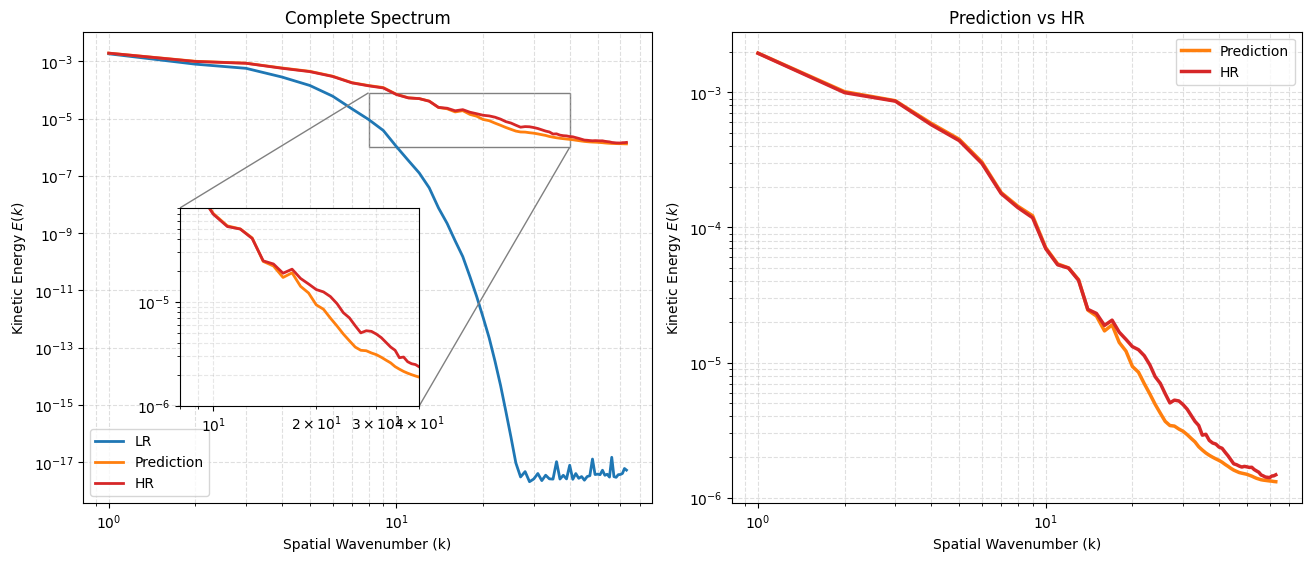

In [9]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Compute spectra
k_lr, E_lr = compute_ek(*lr_np)
k_pred, E_pred = compute_ek(*pred_np)
k_hr, E_hr = compute_ek(*hr_np)

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=100,
    constrained_layout=True
)

# ======================================================
# LEFT PANEL: All curves + inset
# ======================================================

ax1.loglog(k_lr, E_lr, label="LR", lw=2, color="tab:blue")
ax1.loglog(k_pred, E_pred, label="Prediction", lw=2, color="tab:orange")
ax1.loglog(k_hr, E_hr, label="HR", lw=2, color="tab:red")

ax1.set_title("Complete Spectrum")
ax1.set_xlabel("Spatial Wavenumber (k)")
ax1.set_ylabel("Kinetic Energy $E(k)$")
ax1.grid(True, which="both", ls="--", alpha=0.4)
ax1.legend()

# ---------- inset ----------
axins = inset_axes(
    ax1,
    width="42%",
    height="42%",
    loc="lower left",
    borderpad=7,
)

axins.loglog(k_pred, E_pred, color="tab:orange", lw=2)
axins.loglog(k_hr, E_hr, color="tab:red", lw=2)

# Change these until you like the view
axins.set_xlim(8, 40)
axins.set_ylim(1e-6, 8e-5)

axins.grid(True, which="both", ls="--", alpha=0.3)

mark_inset(
    ax1,
    axins,
    loc1=2,
    loc2=4,
    fc="none",
    ec="0.5",
    lw=1,
)

# ======================================================
# RIGHT PANEL: HR vs Prediction only
# ======================================================

ax2.loglog(k_pred, E_pred, label="Prediction", lw=2.5, color="tab:orange")
ax2.loglog(k_hr, E_hr, label="HR", lw=2.5, color="tab:red")

ax2.set_title("Prediction vs HR")
ax2.set_xlabel("Spatial Wavenumber (k)")
ax2.set_ylabel("Kinetic Energy $E(k)$")
ax2.grid(True, which="both", ls="--", alpha=0.4)
ax2.legend()

plt.show()

In [10]:
# ----- NumPy implementation -----

lr_np = lr.squeeze(0).cpu().numpy()
pred_np = output.squeeze(0).detach().cpu().numpy()
hr_np = hr.squeeze(0).cpu().numpy()

k_np, E_np = compute_ek(*pred_np)


# ----- PyTorch implementation -----

spec = KineticEnergySpectrumLoss(size=128)

with torch.no_grad():
    E_torch = spec.compute_spectrum(output).squeeze(0).cpu().numpy()


print(f"NumPy spectrum shape : {E_np.shape}")
print(f"Torch spectrum shape : {E_torch.shape}")

print("Max abs diff :", np.abs(E_np - E_torch).max())
print("Mean abs diff:", np.abs(E_np - E_torch).mean())

NumPy spectrum shape : (63,)
Torch spectrum shape : (63,)
Max abs diff : 1.1641532e-10
Mean abs diff: 3.5116601e-12


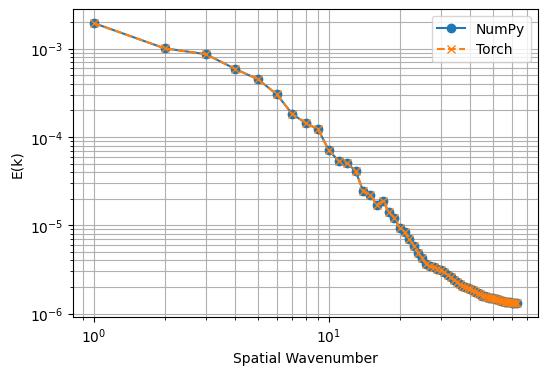

In [11]:
plt.figure(figsize=(6,4))

plt.loglog(k_np, E_np, 'o-', label='NumPy')
plt.loglog(k_np, E_torch, 'x--', label='Torch')

plt.xlabel("Spatial Wavenumber")
plt.ylabel("E(k)")
plt.grid(True, which="both")
plt.legend()
plt.show()

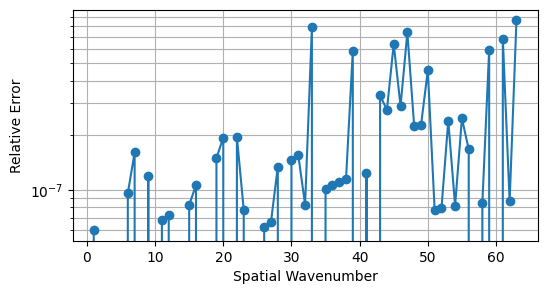

Max relative error: 8.648015e-07


In [12]:
rel_error = np.abs(E_np - E_torch) / (E_np + 1e-12)

plt.figure(figsize=(6,3))
plt.semilogy(k_np, rel_error, "o-")
plt.xlabel("Spatial Wavenumber")
plt.ylabel("Relative Error")
plt.grid(True, which="both")
plt.show()

print("Max relative error:", rel_error.max())

C:\Users\vinic\AppData\Local\Temp\ipykernel_30240\2947398019.py:180: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


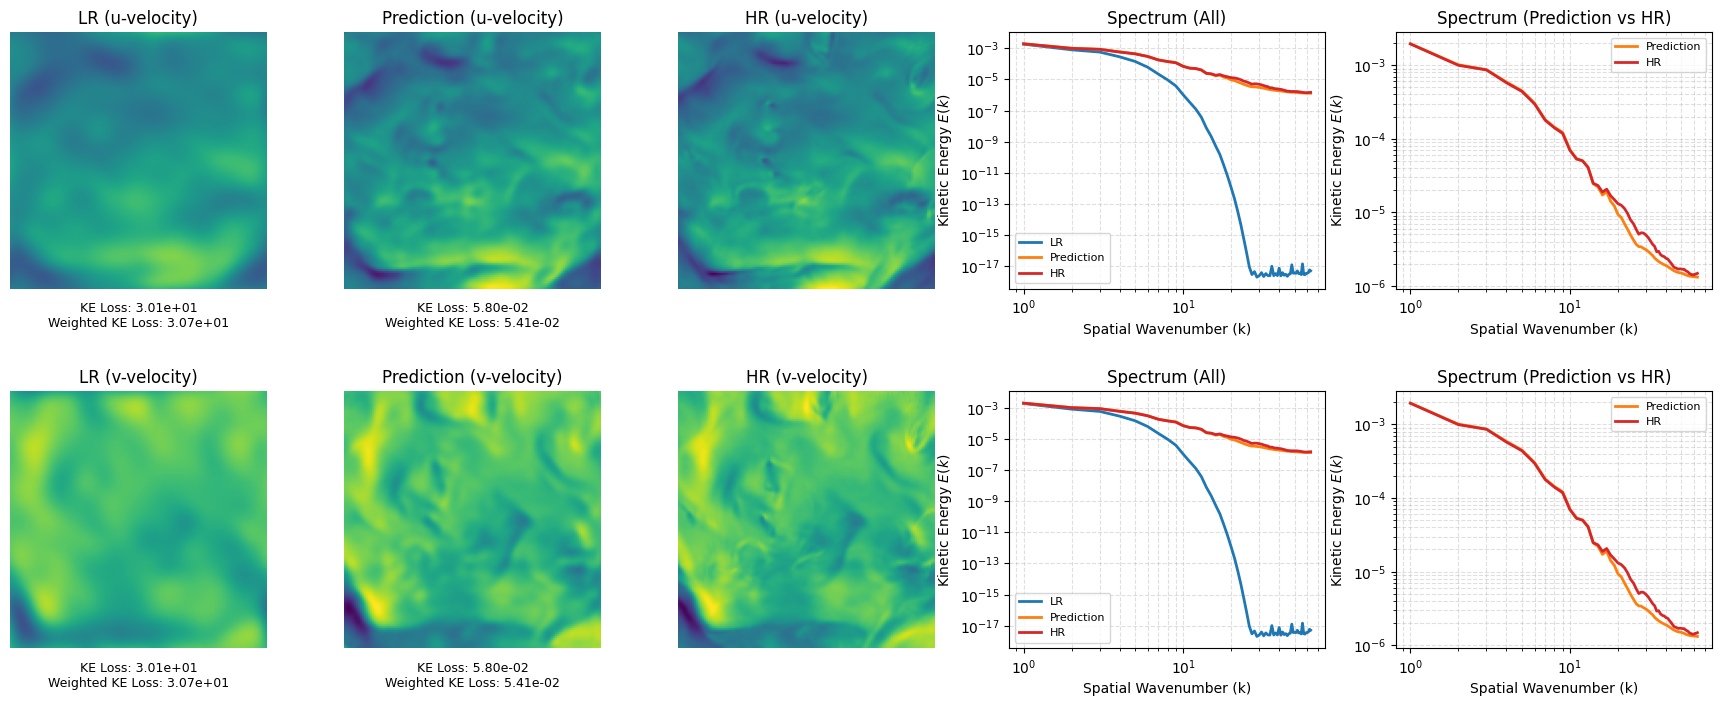

In [16]:
# ==========================================================
# Visualization + Kinetic Energy Spectrum Comparison
# ==========================================================

ke_loss_fn = KineticEnergySpectrumLoss(size=128)
weighted_ke_loss_fn = WeightedKineticEnergySpectrumLoss(size=128)

with torch.no_grad():
    ke_loss_pred = ke_loss_fn(output, hr).item()
    ke_loss_lr = ke_loss_fn(lr, hr).item()
    weighted_ke_loss_pred = weighted_ke_loss_fn(output, hr).item()
    weighted_ke_loss_lr = weighted_ke_loss_fn(lr, hr).item()

# ----------------------------------------------------------
# Compute spectra
# ----------------------------------------------------------

lr_np = lr.squeeze(0).cpu().numpy()
pred_np = output.squeeze(0).detach().cpu().numpy()
hr_np = hr.squeeze(0).cpu().numpy()

k_lr, E_lr = compute_ek(*lr_np)
k_pred, E_pred = compute_ek(*pred_np)
k_hr, E_hr = compute_ek(*hr_np)

# ----------------------------------------------------------
# Figure
# ----------------------------------------------------------

fig, axes = plt.subplots(
    2,
    5,
    figsize=(22, 8),
    gridspec_kw={
        "width_ratios": [1, 1, 1, 1.2, 1.2],
        "wspace": 0.25,
        "hspace": 0.40,
    },
)

variables = ["u-velocity", "v-velocity"]

for row, comp_name in enumerate(variables):

    # Shared color scale
    vmin = min(
        lr_np[row].min(),
        pred_np[row].min(),
        hr_np[row].min(),
    )

    vmax = max(
        lr_np[row].max(),
        pred_np[row].max(),
        hr_np[row].max(),
    )

    # ======================================================
    # LR
    # ======================================================

    axes[row, 0].imshow(
        lr_np[row],
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )

    axes[row, 0].set_title(f"LR ({comp_name})")
    axes[row, 0].axis("off")

    axes[row, 0].text(
        0.5,
        -0.15,
        f"KE Loss: {ke_loss_lr:.2e}\nWeighted KE Loss: {weighted_ke_loss_lr:.2e}",
        transform=axes[row, 0].transAxes,
        ha="center",
        fontsize=9,
    )

    # ======================================================
    # Prediction
    # ======================================================

    axes[row, 1].imshow(
        pred_np[row],
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )

    axes[row, 1].set_title(f"Prediction ({comp_name})")
    axes[row, 1].axis("off")

    axes[row, 1].text(
        0.5,
        -0.15,
        f"KE Loss: {ke_loss_pred:.2e}\nWeighted KE Loss: {weighted_ke_loss_pred:.2e}",
        transform=axes[row, 1].transAxes,
        ha="center",
        fontsize=9,
    )

    # ======================================================
    # HR
    # ======================================================

    axes[row, 2].imshow(
        hr_np[row],
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )

    axes[row, 2].set_title(f"HR ({comp_name})")
    axes[row, 2].axis("off")

    # ======================================================
    # Spectrum (All)
    # ======================================================

    axes[row, 3].loglog(
        k_lr,
        E_lr,
        label="LR",
        color="tab:blue",
        lw=2,
    )

    axes[row, 3].loglog(
        k_pred,
        E_pred,
        label="Prediction",
        color="tab:orange",
        lw=2,
    )

    axes[row, 3].loglog(
        k_hr,
        E_hr,
        label="HR",
        color="tab:red",
        lw=2,
    )

    axes[row, 3].set_title("Spectrum (All)")
    axes[row, 3].set_xlabel("Spatial Wavenumber (k)")
    axes[row, 3].set_ylabel("Kinetic Energy $E(k)$")
    axes[row, 3].grid(True, which="both", ls="--", alpha=0.4)
    axes[row, 3].legend(fontsize=8)

    # ======================================================
    # Spectrum (Prediction vs HR)
    # ======================================================

    axes[row, 4].loglog(
        k_pred,
        E_pred,
        label="Prediction",
        color="tab:orange",
        lw=2,
        markersize=3,
    )

    axes[row, 4].loglog(
        k_hr,
        E_hr,
        label="HR",
        color="tab:red",
        lw=2,
        markersize=3,
    )

    axes[row, 4].set_title("Spectrum (Prediction vs HR)")
    axes[row, 4].set_xlabel("Spatial Wavenumber (k)")
    axes[row, 4].set_ylabel("Kinetic Energy $E(k)$")
    axes[row, 4].grid(True, which="both", ls="--", alpha=0.4)
    axes[row, 4].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    "ke_spectrum_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()